# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170406          # <-- your full roll number
NAME = "Piyush"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170406   Name: Piyush   Fingerprint: 8E95BC9D   Tickets: 13

Ticket_ID                                                                                 Ticket_Text
      T01            Printer is showing an error while uploading the file. Is there another solution?
      T02            Projector is not working after resetting my password. Is there another solution?
      T03                                                Call me on +91 98765 43210 or 0175-239-3201.
      T04          VPN stopped responding when connected to campus Wi-Fi. I have tried several times!
      T05         I cannot access the student portal after restarting the system. Can you check this?
      T06                       I tried restarting the password since yesterday. It worked yesterday.
      T07                                                             Is it fixed?? Pls reply ASAP :(
      T08                                                        Python 3.12 was installed yesterday.
    

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
results = []

for _, row in df.iterrows():
    output = process_ticket(row["Ticket_Text"])

    results.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(output["sentences"]),
        "Tokens": len(output["tokens"]),
        "Punctuation": len(output["punct"]),
        "Stopwords": len(output["stops"]),
        "Unique Tokens": len(set(output["tokens"])),
        "Final Tokens": len(output["final"])
    })

summary = pd.DataFrame(results)

total = summary.select_dtypes(include="number").sum()
total["Ticket_ID"] = "TOTAL"

summary = pd.concat([summary, pd.DataFrame([total])], ignore_index=True)

print(summary.to_string(index=False))


Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique Tokens  Final Tokens
      T01          2      15            2          6             14             7
      T02          2      14            2          6             13             6
      T03          1       9            1          3              9             5
      T04          2      15            2          4             15             9
      T05          2      17            2          9             15             6
      T06          2      12            2          3             10             7
      T07          2      10            4          2              9             4
      T08          1       6            1          1              6             4
      T09          2      14            2          5             14             7
      T10          2      18            2          9             16             7
      T11          2      14            2          6             12             6
      T12       

In [6]:
ticket = df.loc[df["Ticket_ID"] == "T01", "Ticket_Text"].iloc[0]

output = process_ticket(ticket)

print("Ticket:", ticket)
print("Tokens:", output["tokens"])
print("Punctuation:", output["punct"])
print("Stopwords:", output["stops"])
print("Final Tokens:", output["final"])


Ticket: Printer is showing an error while uploading the file. Is there another solution?
Tokens: ['printer', 'is', 'showing', 'an', 'error', 'while', 'uploading', 'the', 'file', '.', 'is', 'there', 'another', 'solution', '?']
Punctuation: ['.', '?']
Stopwords: ['is', 'an', 'while', 'the', 'is', 'there']
Final Tokens: ['printer', 'showing', 'error', 'uploading', 'file', 'another', 'solution']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Pls, ASAP

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

# Use the test lines already provided in your notebook
for text in TEST_LINES:
    print("\nText:", text)

    # 1. Words longer than 5 letters
    long_words = re.findall(r'\b[A-Za-z]{6,}\b', text)

    # 2. Numbers, decimals, and version numbers
    numbers = re.findall(r'\b\d+(?:\.\d+)*\b', text)

    # 3. Capitalized words
    capitalized = re.findall(r'\b[A-Z][a-zA-Z]*\b', text)

    # 4. Words beginning with a vowel
    vowel_words = re.findall(r'\b[aeiouAEIOU][A-Za-z]*\b', text)

    # 5. Replace email addresses, URLs, and phone numbers
    cleaned = re.sub(
        r'[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}',
        '<EMAIL>', text
    )
    cleaned = re.sub(r'https?://\S+|www\.\S+', '<URL>', cleaned)
    cleaned = re.sub(r'(?<!\w)\+?\d[\d -]{7,}\d(?!\w)', '<PHONE>', cleaned)

    print("Long words:", long_words)
    print("Numbers:", numbers)
    print("Capitalized words:", capitalized)
    print("Words beginning with vowels:", vowel_words)
    print("Replaced text:", cleaned)


Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Long words: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Words beginning with vowels: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
Replaced text: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Long words: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words: ['Call', 'Version', 'Rs']
Words beginning with vowels: ['or', 'is']
Replaced text: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Long words: []
Numbers: ['5.30']
Capitalized words: ['The']
Words beginning with vowels: ['of', 'art', 'isn', 'open', 'in', 'at']
R

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 3

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"""https?://\S+|www\.\S+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+?\d[\d -]{7,}\d|\d+(?:\.\d+)*|[A-Za-z]+(?:[-'][A-Za-z]+)*"""

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)


# Run on TEST_LINES
for text in TEST_LINES:
    print("\nText:", text)
    print("Custom:", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))


# Run on tickets
for _, row in df.iterrows():
    text = row["Ticket_Text"]
    print("\nTicket:", row["Ticket_ID"])
    print("Custom:", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))


Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Custom: ['The', 'state-of-the-art', 'lab', "isn't",

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 13

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet
import pandas as pd

# 1. Collect unique final tokens from all tickets
unique_tokens = sorted({
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["final"]
})

# 2. Initialize the four methods
porter = PorterStemmer()
lancaster = LancasterStemmer()

# Custom suffix rule selected after inspecting ticket words
regex_stemmer = RegexpStemmer(r"(ing|ed|es|s)$", min=4)

lemmatizer = WordNetLemmatizer()

# 3. Convert POS tags to WordNet POS
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

# 4. Get POS tags for the unique tokens
tagged_words = pos_tag(unique_tokens)

# 5. Apply all four methods
results = []

for word, tag in tagged_words:
    pos = get_wordnet_pos(tag)

    results.append({
        "Word": word,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regex_stemmer.stem(word),
        "Lemma": lemmatizer.lemmatize(word, pos=pos)
    })

comparison = pd.DataFrame(results)

# 6. Show only words whose outputs differ
output_columns = ["Porter", "Lancaster", "Regexp", "Lemma"]

different = comparison[
    comparison[output_columns].nunique(axis=1) > 1
]

print(different.to_string(index=False))

      Word    Porter Lancaster     Regexp      Lemma
    access    access    access      acces     access
   another     anoth     anoth    another    another
assignment    assign    assign assignment assignment
      call      call       cal       call       call
    campus     campu      camp      campu     campus
  computer    comput    comput   computer   computer
  deadline   deadlin   deadlin   deadline   deadline
     error     error        er      error      error
      file      file       fil       file       file
 installed    instal    instal    install     instal
    jammed       jam       jam       jamm     jammed
   opening      open        op       open       open
       pls        pl       pls        pls        pls
    portal    portal      port     portal     portal
   printer   printer     print    printer    printer
 projector projector   project  projector  projector
     reply     repli     reply      reply      reply
 resetting     reset     reset     resett     

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Corpus Statistics
             Corpus  Tokens  Unique Tokens    TTR
    S1 - All tokens     165             87 0.5273
S2 - No punctuation     139             81 0.5827
  S3 - Final tokens      79             57 0.7215
  S4 - Porter stems      79             55 0.6962

Top 10 words in S1:
[('.', 16), ('the', 10), ('is', 8), ('?', 5), ('i', 5), ('yesterday', 5), ('it', 5), ('another', 3), ('tried', 3), ('was', 3)]

Top 10 words in S3:
[('yesterday', 5), ('another', 3), ('tried', 3), ('printer', 2), ('showing', 2), ('error', 2), ('solution', 2), ('projector', 2), ('working', 2), ('password', 2)]


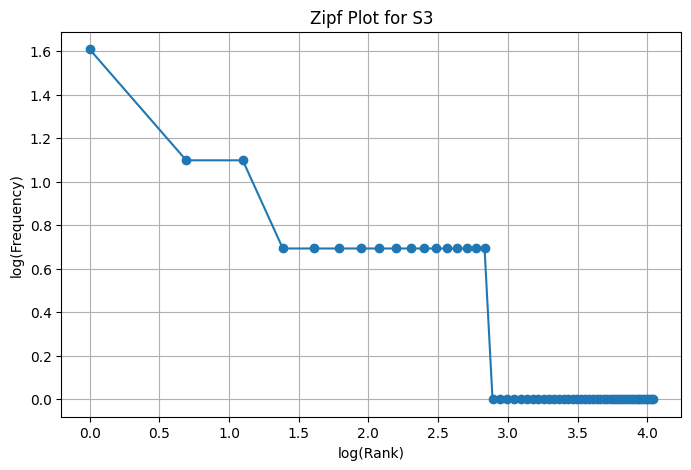


Top 5 bigrams in S1:
[(('yesterday', '.'), 4), (('.', 'is'), 3), (('.', 'it'), 3), (('is', 'showing'), 2), (('showing', 'an'), 2)]

Top 5 bigrams in S3:
[(('showing', 'error'), 2), (('another', 'solution'), 2), (('projector', 'working'), 2), (('tried', 'several'), 2), (('several', 'times'), 2)]


In [10]:
import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer

# S1: All tokens, including punctuation and stopwords
S1 = [
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["tokens"]
]

# S2: Tokens without punctuation
S2 = [
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["tokens"]
    if not all(ch in ".,!?;:'\"-()[]{}" for ch in token)
]

# S3: Final tokens (without punctuation and stopwords)
S3 = [
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["final"]
]

# S4: S3 after Porter stemming
porter = PorterStemmer()
S4 = [porter.stem(token) for token in S3]


# Corpus statistics
def corpus_stats(name, tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0

    return {
        "Corpus": name,
        "Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    }


stats = pd.DataFrame([
    corpus_stats("S1 - All tokens", S1),
    corpus_stats("S2 - No punctuation", S2),
    corpus_stats("S3 - Final tokens", S3),
    corpus_stats("S4 - Porter stems", S4)
])

print("Corpus Statistics")
print(stats.to_string(index=False))


# Top 10 words of S1 and S3
print("\nTop 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))


# Log(rank) vs log(frequency) for S3
frequencies = sorted(Counter(S3).values(), reverse=True)
ranks = range(1, len(frequencies) + 1)

plt.figure(figsize=(8, 5))
plt.plot(
    [math.log(r) for r in ranks],
    [math.log(f) for f in frequencies],
    marker="o"
)
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Zipf Plot for S3")
plt.grid(True)
plt.show()


# Top 5 bigrams of S1 and S3
print("\nTop 5 bigrams in S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR changes from S1 to S4 because both the number of unique tokens and the total number of tokens change during preprocessing.